In [122]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42

## Dataset and Setup

In [123]:
file_path = "data_banknote_authentication.txt"

columns = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(
    file_path,
    header=None,
    names=columns,
    sep=",",
    skipinitialspace=True
)

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")
print(f"Number of samples: {len(df)}")
print(f"Number of features: {len(columns) - 1}")
print(f"Target classes: {sorted(df['class'].unique())}")

display(df.head())

Dataset loaded successfully.
Shape: (1372, 5)
Number of samples: 1372
Number of features: 4
Target classes: [np.int64(0), np.int64(1)]


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## Data Exploration

In [124]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [125]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [126]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 24


In [127]:
print("\nClass distribution:")
print(df["class"].value_counts().sort_index())


Class distribution:
class
0    762
1    610
Name: count, dtype: int64


In [128]:
print("\nFeature statistics:")
display(df.describe().T)

if df.isnull().any().any():
    raise ValueError("The dataset contains missing values.")

if not set(df["class"].unique()).issubset({0, 1}):
    raise ValueError("Expected binary target labels 0 and 1.")

if df.shape[1] != 5:
    raise ValueError("Expected four features and one target column.")


Feature statistics:


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
class,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


# Part A — Decision Tree from Scratch

## Train-Test Split and Two-Feature Dataset

In [129]:
# Select two features for decision-boundary visualization
features_2d = ["variance", "skewness"]

X_2d = df[features_2d].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# Consistent stratified split for all models
X_train_2d, X_test_2d, y_train, y_test = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train-test split completed.")
print(f"Training samples: {len(X_train_2d)}")
print(f"Testing samples: {len(X_test_2d)}")
print(f"Training feature shape: {X_train_2d.shape}")
print(f"Testing feature shape: {X_test_2d.shape}")

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nFeatures used for 2D visualization:", features_2d)

Train-test split completed.
Training samples: 1097
Testing samples: 275
Training feature shape: (1097, 2)
Testing feature shape: (275, 2)

Training class distribution:
0    609
1    488
Name: count, dtype: int64

Testing class distribution:
0    153
1    122
Name: count, dtype: int64

Features used for 2D visualization: ['variance', 'skewness']


## Gini Impurity and Entropy

In [130]:
def gini_impurity(y):
    """Calculate Gini impurity for a set of class labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    """Calculate entropy for a set of class labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


# Evaluate impurity at the root of the training set
root_gini = gini_impurity(y_train)
root_entropy = entropy(y_train)

print("Impurity measures implemented from scratch.")
print(f"Training samples: {len(y_train)}")
print(f"Class 0 proportion: {np.mean(y_train == 0):.4f}")
print(f"Class 1 proportion: {np.mean(y_train == 1):.4f}")
print(f"\nRoot Gini impurity: {root_gini:.4f}")
print(f"Root entropy: {root_entropy:.4f}")

# Verify both measures on pure and mixed nodes
pure_node = np.array([0, 0, 0, 0])
mixed_node = np.array([0, 0, 1, 1])

print("\nVerification:")
print(f"Pure node — Gini: {gini_impurity(pure_node):.4f}, "
      f"Entropy: {entropy(pure_node):.4f}")
print(f"Mixed node — Gini: {gini_impurity(mixed_node):.4f}, "
      f"Entropy: {entropy(mixed_node):.4f}")

Impurity measures implemented from scratch.
Training samples: 1097
Class 0 proportion: 0.5552
Class 1 proportion: 0.4448

Root Gini impurity: 0.4939
Root entropy: 0.9912

Verification:
Pure node — Gini: 0.0000, Entropy: -0.0000
Mixed node — Gini: 0.5000, Entropy: 1.0000


## Best Feature-Threshold Split

In [131]:
def best_split(X, y, criterion="gini"):
    """Find the feature and threshold with the lowest weighted child impurity."""
    if criterion not in ("gini", "entropy"):
        raise ValueError("criterion must be 'gini' or 'entropy'.")

    impurity_func = gini_impurity if criterion == "gini" else entropy
    n_samples, n_features = X.shape

    parent_impurity = impurity_func(y)
    best_gain = 0.0
    best_result = None

    for feature_idx in range(n_features):
        values = np.unique(X[:, feature_idx])

        if len(values) < 2:
            continue

        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X[:, feature_idx] <= threshold
            right_mask = ~left_mask

            if not left_mask.any() or not right_mask.any():
                continue

            y_left = y[left_mask]
            y_right = y[right_mask]

            weighted_impurity = (
                len(y_left) / n_samples * impurity_func(y_left)
                + len(y_right) / n_samples * impurity_func(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_result = {
                    "feature_idx": feature_idx,
                    "threshold": float(threshold),
                    "gain": float(gain),
                    "left_size": len(y_left),
                    "right_size": len(y_right),
                    "weighted_impurity": float(weighted_impurity)
                }

    return best_result


# Find the best root split using both criteria
for criterion in ("gini", "entropy"):
    result = best_split(X_train_2d, y_train, criterion=criterion)

    print(f"\nCriterion: {criterion}")
    if result is not None:
        print(f"Feature: {features_2d[result['feature_idx']]}")
        print(f"Threshold: {result['threshold']:.6f}")
        print(f"Information gain / impurity reduction: {result['gain']:.6f}")
        print(f"Weighted child impurity: {result['weighted_impurity']:.6f}")
        print(f"Left samples: {result['left_size']}")
        print(f"Right samples: {result['right_size']}")
    else:
        print("No valid split found.")


Criterion: gini
Feature: variance
Threshold: 0.765100
Information gain / impurity reduction: 0.242095
Weighted child impurity: 0.251822
Left samples: 593
Right samples: 504

Criterion: entropy
Feature: variance
Threshold: 0.765100
Information gain / impurity reduction: 0.402805
Weighted child impurity: 0.588401
Left samples: 593
Right samples: 504


In [ ]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'.")

        if max_depth is not None and max_depth < 0:
            raise ValueError("max_depth must be non-negative or None.")

        if min_samples_split < 2:
            raise ValueError("min_samples_split must be at least 2.")

        if min_samples_leaf < 1:
            raise ValueError("min_samples_leaf must be at least 1.")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.tree_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if X.ndim != 2 or len(X) != len(y) or len(y) == 0:
            raise ValueError("X and y must contain matching, non-empty samples.")

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains non-finite values.")

        self.n_features_in_ = X.shape[1]
        self.tree_ = self._build_tree(X, y, depth=0)
        return self

    def _build_tree(self, X, y, depth):
        prediction = int(np.bincount(y).argmax())
        impurity_func = gini_impurity if self.criterion == "gini" else entropy

        node = {
            "samples": len(y),
            "impurity": float(impurity_func(y)),
            "prediction": prediction
        }

        # Stop when the node is pure or cannot be split further.
        if len(np.unique(y)) == 1:
            return node

        if (
            self.max_depth is not None
            and depth >= self.max_depth
        ):
            return node

        if len(y) < self.min_samples_split:
            return node

        split = best_split(X, y, criterion=self.criterion)

        if split is None:
            return node

        feature_idx = split["feature_idx"]
        threshold = split["threshold"]

        left_mask = X[:, feature_idx] <= threshold
        right_mask = ~left_mask

        # Do not create children that violate the leaf-size requirement.
        if (
            left_mask.sum() < self.min_samples_leaf
            or right_mask.sum() < self.min_samples_leaf
        ):
            return node

        node.update({
            "feature_idx": feature_idx,
            "threshold": threshold,
            "gain": split["gain"],
            "left": self._build_tree(
                X[left_mask], y[left_mask], depth + 1
            ),
            "right": self._build_tree(
                X[right_mask], y[right_mask], depth + 1
            )
        })

        return node

    def predict(self, X):
        if self.tree_ is None:
            raise ValueError("Call fit() before predict().")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError(
                f"X must have {self.n_features_in_} features."
            )

        predictions = []

        for sample in X:
            node = self.tree_

            while "feature_idx" in node:
                feature_idx = node["feature_idx"]
                threshold = node["threshold"]

                if sample[feature_idx] <= threshold:
                    node = node["left"]
                else:
                    node = node["right"]

            predictions.append(node["prediction"])

        return np.asarray(predictions, dtype=int)


def _get_manual_tree_depth(node):
    if "feature_idx" not in node:
        return 0

    return 1 + max(
        _get_manual_tree_depth(node["left"]),
        _get_manual_tree_depth(node["right"])
    )


def count_manual_leaves(node):
    if "feature_idx" not in node:
        return 1

    return (
        count_manual_leaves(node["left"])
        + count_manual_leaves(node["right"])
    )


print("Manual decision tree class defined successfully.")

## Recursive Construction and Prediction

In [ ]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

print("Manual decision tree initialized.")
print("Criterion:", manual_tree.criterion)
print("Maximum allowed depth:", manual_tree.max_depth)
print("Minimum samples required to split:", manual_tree.min_samples_split)
print("Minimum samples per leaf:", manual_tree.min_samples_leaf)

Manual decision tree class defined successfully.
Criterion: gini
Maximum depth: 5


## Manual and Scikit-learn Comparison

In [153]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)

start_time = time.perf_counter()
manual_tree.fit(X_train_2d, y_train)
manual_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_manual = manual_tree.predict(X_test_2d)
manual_predict_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_tree.fit(X_train_2d, y_train)
sklearn_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_sklearn = sklearn_tree.predict(X_test_2d)
sklearn_predict_time = time.perf_counter() - start_time

comparison = pd.DataFrame([
    {
        "Model": "Manual Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred_manual),
        "Precision": precision_score(y_test, y_pred_manual, zero_division=0),
        "Recall": recall_score(y_test, y_pred_manual, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_manual, zero_division=0),
        "Training time (s)": manual_train_time,
        "Prediction time (s)": manual_predict_time
    },
    {
        "Model": "Scikit-learn Decision Tree",
        "Accuracy": accuracy_score(y_test, y_pred_sklearn),
        "Precision": precision_score(y_test, y_pred_sklearn, zero_division=0),
        "Recall": recall_score(y_test, y_pred_sklearn, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_sklearn, zero_division=0),
        "Training time (s)": sklearn_train_time,
        "Prediction time (s)": sklearn_predict_time
    }
])

display(comparison.round(5))

print("Manual tree actual depth:", _get_manual_tree_depth(manual_tree.tree_))
print("Scikit-learn tree depth:", sklearn_tree.get_depth())
print(
    "Predictions identical:",
    np.array_equal(y_pred_manual, y_pred_sklearn)
)

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Decision Tree,0.93091,0.88148,0.97541,0.92607,0.38475,0.00030
1,Scikit-learn Decision Tree,0.93091,0.88148,0.97541,0.92607,0.00194,0.00031


Manual tree actual depth: 5
Scikit-learn tree depth: 5
Predictions identical: True


## Manual Tree Structure and Split Rules

In [133]:
def print_manual_tree(node, feature_names, depth=0):
    indent = "  " * depth

    if "feature_idx" not in node:
        print(
            f"{indent}Predict class {node['prediction']} "
            f"(samples={node['samples']}, "
            f"impurity={node['impurity']:.4f})"
        )
        return

    feature = feature_names[node["feature_idx"]]
    threshold = node["threshold"]

    print(
        f"{indent}IF {feature} <= {threshold:.4f} "
        f"(gain={node['gain']:.4f}, samples={node['samples']})"
    )
    print(f"{indent}  LEFT:")
    print_manual_tree(node["left"], feature_names, depth + 2)

    print(f"{indent}ELSE ({feature} > {threshold:.4f}):")
    print_manual_tree(node["right"], feature_names, depth + 2)


print("MANUAL DECISION TREE SPLIT RULES")
print("=" * 45)
print_manual_tree(manual_tree.tree_, features_2d)

MANUAL DECISION TREE SPLIT RULES
IF variance <= 0.7651 (gain=0.2421, samples=1097)
  LEFT:
    IF skewness <= 5.1608 (gain=0.1489, samples=593)
      LEFT:
        IF variance <= 0.3202 (gain=0.0287, samples=464)
          LEFT:
            IF variance <= -0.4586 (gain=0.0052, samples=413)
              LEFT:
                IF skewness <= 0.0548 (gain=0.0020, samples=346)
                  LEFT:
                    Predict class 1 (samples=208, impurity=0.0000)
                ELSE (skewness > 0.0548):
                    Predict class 1 (samples=138, impurity=0.1219)
            ELSE (variance > -0.4586):
                IF skewness <= -0.1666 (gain=0.0574, samples=67)
                  LEFT:
                    Predict class 1 (samples=27, impurity=0.4664)
                ELSE (skewness > -0.1666):
                    Predict class 1 (samples=40, impurity=0.0488)
        ELSE (variance > 0.3202):
            IF skewness <= 3.2197 (gain=0.1145, samples=51)
              LEFT:
       

## Manual Decision Boundary

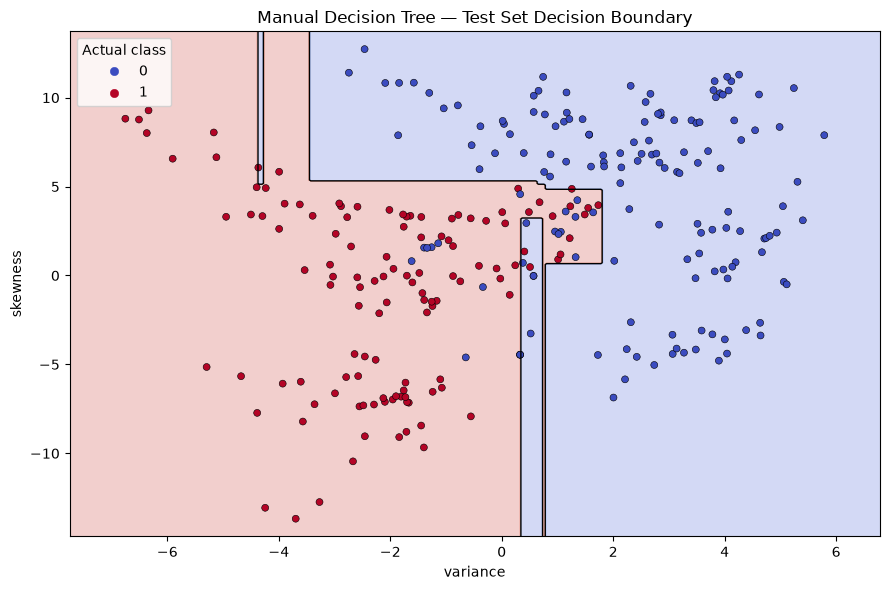

In [134]:
def plot_decision_boundary(model, X, y, title, feature_names):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1)

    scatter = plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", linewidths=0.4, s=25
    )

    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.legend(
        *scatter.legend_elements(),
        title="Actual class",
        loc="best"
    )
    plt.tight_layout()
    plt.show()


plot_decision_boundary(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree — Test Set Decision Boundary",
    features_2d
)

## Scikit-learn Visualization and Comparison

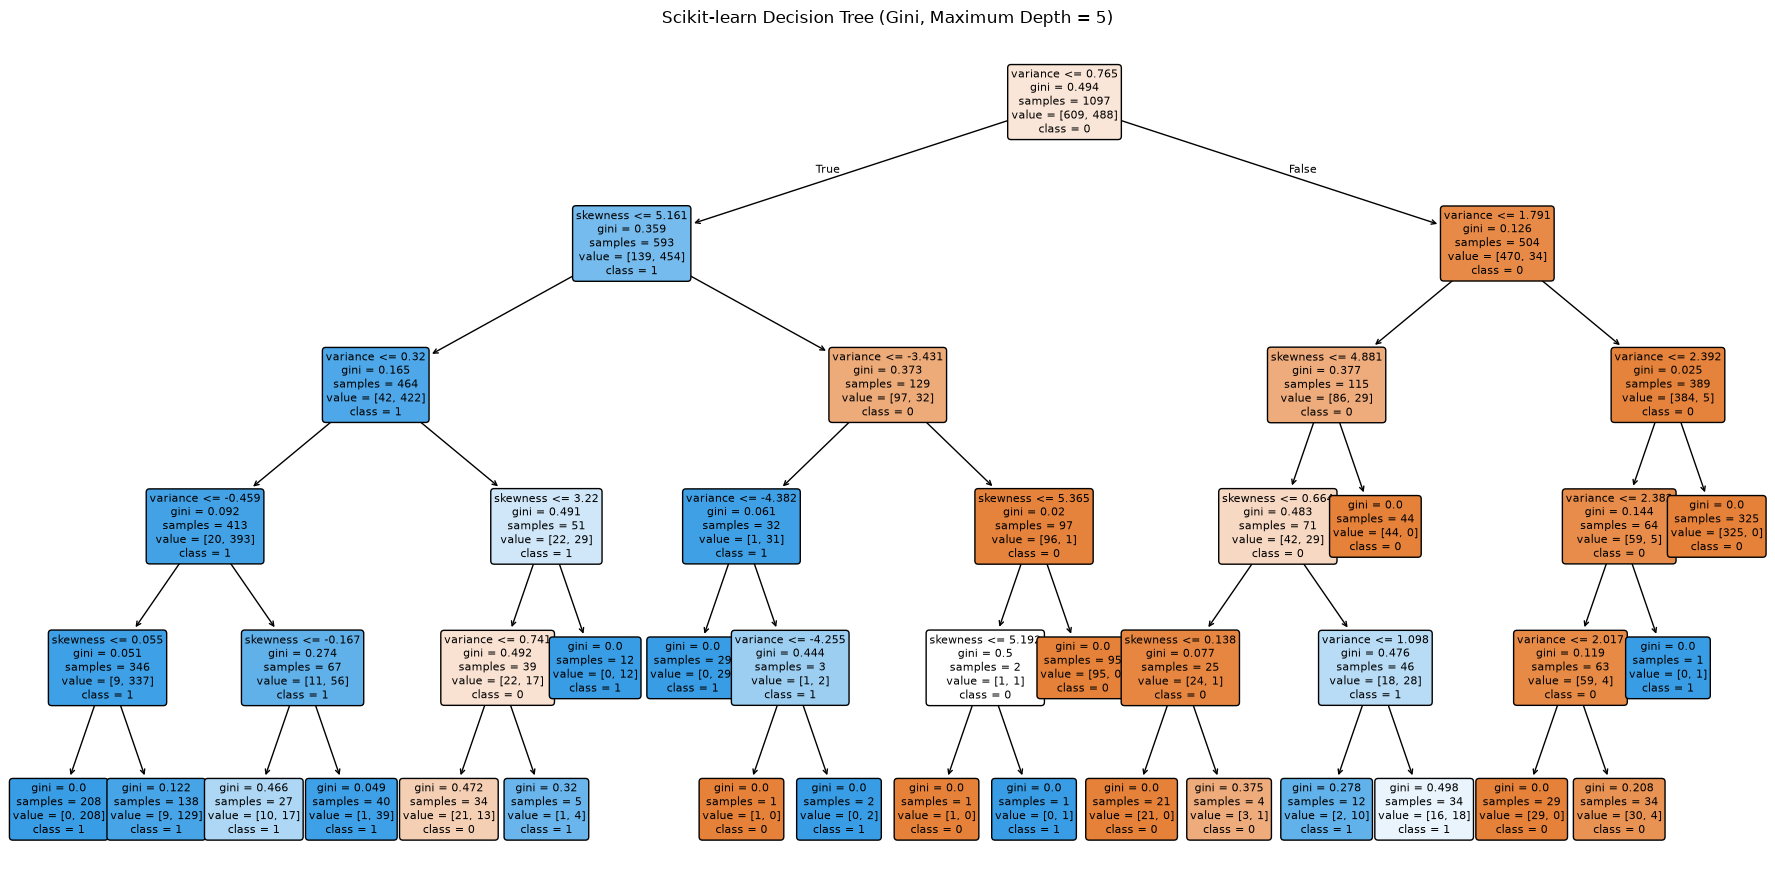

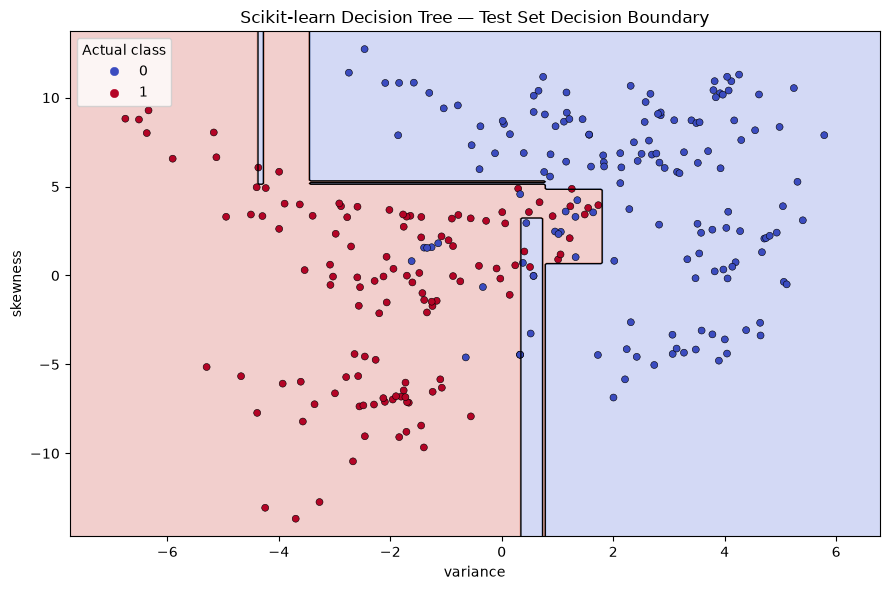

In [155]:

plt.figure(figsize=(18, 9))

plot_tree(
    sklearn_tree,
    feature_names=features_2d,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Scikit-learn Decision Tree (Gini, Maximum Depth = 5)")
plt.tight_layout()
plt.show()

plot_decision_boundary(
    sklearn_tree,
    X_test_2d,
    y_test,
    "Scikit-learn Decision Tree — Test Set Decision Boundary",
    features_2d
)


## Comparison of Gini and Entropy Criteria

In [136]:
criterion_results = []

for criterion in ["gini", "entropy"]:
    model = ManualDecisionTree(
        criterion=criterion,
        max_depth=5
    )

    start = time.perf_counter()
    model.fit(X_train_2d, y_train)
    train_time = time.perf_counter() - start

    predictions = model.predict(X_test_2d)

    criterion_results.append({
        "Criterion": criterion,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Training time (s)": train_time
    })

criterion_comparison = pd.DataFrame(criterion_results)
display(criterion_comparison.round(5))

,Criterion,Accuracy,Precision,Recall,F1-score,Training time (s)
0,gini,0.93091,0.88148,0.97541,0.92607,0.37855
1,entropy,0.93455,0.90000,0.95902,0.92857,0.32004


## Effect of Maximum Depth

In [ ]:
depth_results = []

for depth in [1, 2, 3, 5, 10, None]:
    model = ManualDecisionTree(
        criterion="gini",
        max_depth=depth
    )

    start = time.perf_counter()
    model.fit(X_train_2d, y_train)
    train_time = time.perf_counter() - start

    train_predictions = model.predict(X_train_2d)
    test_predictions = model.predict(X_test_2d)

    depth_results.append({
        "Max depth": "None" if depth is None else depth,
        "Actual depth": _get_manual_tree_depth(model.tree_),
        "Train accuracy": accuracy_score(y_train, train_predictions),
        "Test accuracy": accuracy_score(y_test, test_predictions),
        "Training time (s)": train_time
    })


depth_comparison = pd.DataFrame(depth_results)
display(depth_comparison.round(5))

,Max depth,Actual depth,Train accuracy,Test accuracy,Training time (s)
0,1,1,0.84230,0.82909,0.10047
1,2,2,0.90155,0.87636,0.18192
2,3,3,0.92890,0.90909,0.28055
3,5,5,0.94804,0.93091,0.37139
4,10,10,0.99544,0.92000,0.45296
5,None,14,1.00000,0.92000,0.43832


## Training and Testing Accuracy by Depth

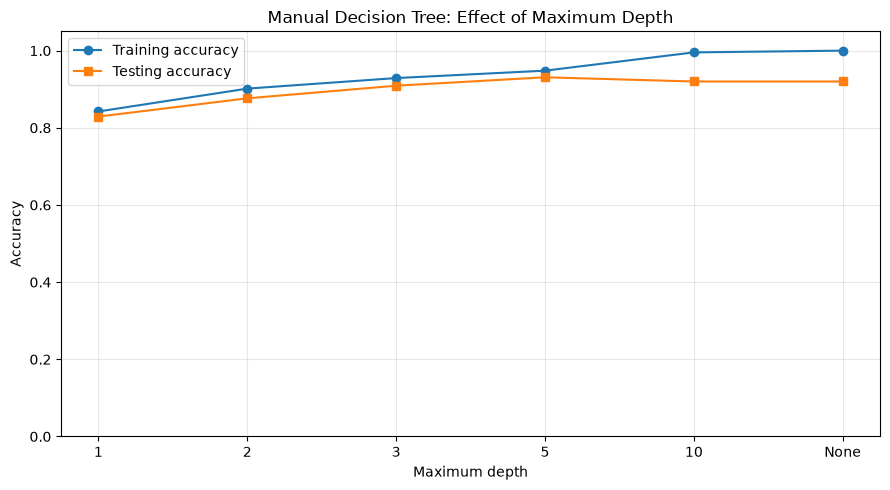

In [138]:
plot_depths = depth_comparison["Max depth"].astype(str)

plt.figure(figsize=(9, 5))
plt.plot(
    plot_depths,
    depth_comparison["Train accuracy"],
    marker="o",
    label="Training accuracy"
)
plt.plot(
    plot_depths,
    depth_comparison["Test accuracy"],
    marker="s",
    label="Testing accuracy"
)

plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Manual Decision Tree: Effect of Maximum Depth")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Part B: Linear SVM from Scratch

## Feature Scaling and Binary Label Encoding

In [139]:
# Fit the scaler ONLY on training data to prevent data leakage
svm_scaler = StandardScaler()

X_train_svm = svm_scaler.fit_transform(X_train_2d)
X_test_svm = svm_scaler.transform(X_test_2d)

# Convert labels from {0, 1} to {-1, +1}
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Feature scaling completed.")
print("Training feature means:", np.round(X_train_svm.mean(axis=0), 4))
print("Training feature standard deviations:",
      np.round(X_train_svm.std(axis=0), 4))

print("\nTraining feature shape:", X_train_svm.shape)
print("Testing feature shape:", X_test_svm.shape)

print("\nOriginal labels:", np.unique(y_train))
print("SVM labels:", np.unique(y_train_svm))
print("Training label distribution:")
print(pd.Series(y_train_svm).value_counts().sort_index())

Feature scaling completed.
Training feature means: [-0. -0.]
Training feature standard deviations: [1. 1.]

Training feature shape: (1097, 2)
Testing feature shape: (275, 2)

Original labels: [0 1]
SVM labels: [-1  1]
Training label distribution:
-1    609
 1    488
Name: count, dtype: int64


## Hinge Loss and Gradient Descent from Scratch

In [140]:
class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=1e-5, n_iterations=10000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim != 2 or len(X) != len(y) or len(y) == 0:
            raise ValueError("Invalid training data dimensions.")
        if not np.all(np.isin(y, [-1, 1])):
            raise ValueError("Labels must be -1 and +1.")
        if self.C <= 0 or self.learning_rate <= 0 or self.n_iterations < 1:
            raise ValueError("C, learning rate, and iterations must be positive.")

        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history_ = []

        for iteration in range(self.n_iterations):
            margins = y * (X @ self.w + self.b)
            violating = margins < 1

            # Conventional primal objective:
            # 0.5 * ||w||^2 + C * sum(max(0, 1 - y*f(x)))
            grad_w = self.w - self.C * (X[violating].T @ y[violating])
            grad_b = -self.C * np.sum(y[violating])

            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            if iteration % 100 == 0 or iteration == self.n_iterations - 1:
                current_margins = y * (X @ self.w + self.b)
                hinge_loss = np.maximum(0, 1 - current_margins).sum()
                objective = 0.5 * np.dot(self.w, self.w) + self.C * hinge_loss
                self.loss_history_.append(objective)

        return self

    def decision_function(self, X):
        if self.w is None:
            raise ValueError("Call fit() before prediction.")
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


## Initial Training and Evaluation

Corrected manual SVM trained.
Weights: [-1.9856 -1.24  ]
Bias: -0.2302
Final objective: 311.9736
Test accuracy: 0.8764
Test precision: 0.8492
Test recall: 0.877
Test F1-score: 0.8629
Margin violations: 316 / 1097


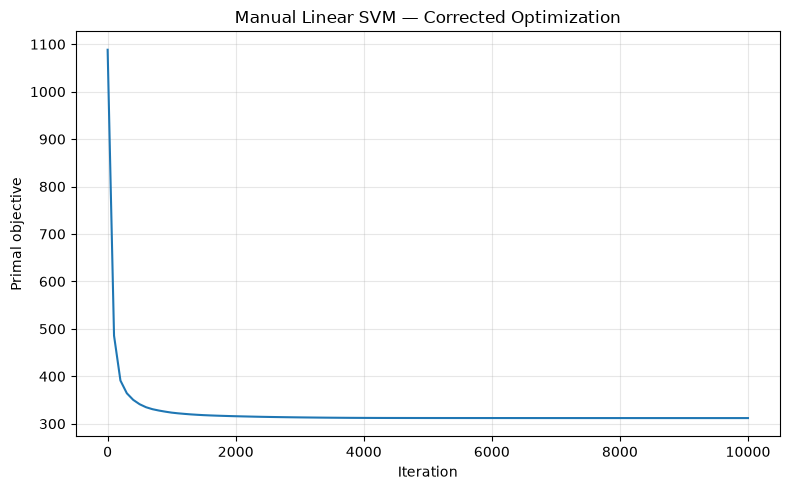

In [141]:
manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=1e-5,
    n_iterations=10000
)

start_time = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
manual_svm_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_svm_signed = manual_svm.predict(X_test_svm)
manual_svm_predict_time = time.perf_counter() - start_time

y_pred_svm = np.where(y_pred_svm_signed == -1, 0, 1)

margin_violations = (
    y_train_svm * manual_svm.decision_function(X_train_svm) < 1
)

print("Corrected manual SVM trained.")
print("Weights:", np.round(manual_svm.w, 4))
print("Bias:", round(manual_svm.b, 4))
print("Final objective:", round(manual_svm.loss_history_[-1], 4))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print("Test precision:", round(precision_score(y_test, y_pred_svm, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, y_pred_svm, zero_division=0), 4))
print("Test F1-score:", round(f1_score(y_test, y_pred_svm, zero_division=0), 4))
print("Margin violations:", int(margin_violations.sum()), "/", len(y_train_svm))

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(len(manual_svm.loss_history_)) * 100,
    manual_svm.loss_history_
)
plt.xlabel("Iteration")
plt.ylabel("Primal objective")
plt.title("Manual Linear SVM — Corrected Optimization")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Effect of Regularization Parameter C

In [142]:
C_results = []

for C_value in [0.01, 0.1, 1.0, 10.0]:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=1e-5,
        n_iterations=10000
    )

    model.fit(X_train_svm, y_train_svm)
    train_pred = model.predict(X_train_svm)
    test_pred = model.predict(X_test_svm)

    C_results.append({
        "C": C_value,
        "Train accuracy": accuracy_score(y_train_svm, train_pred),
        "Test accuracy": accuracy_score(y_test_svm, test_pred),
        "Weight norm": np.linalg.norm(model.w),
        "Margin violations": int(
            np.sum(y_train_svm * model.decision_function(X_train_svm) < 1)
        ),
        "Final objective": model.loss_history_[-1]
    })

C_comparison = pd.DataFrame(C_results)
display(C_comparison.round(5))

,C,Train accuracy,Test accuracy,Weight norm,Margin violations,Final objective
0,0.01,0.88423,0.88727,0.72138,842,5.26730
1,0.10,0.88058,0.89091,1.63627,407,33.85632
2,1.00,0.87967,0.87636,2.34103,316,311.97356
3,10.00,0.88058,0.87636,2.42836,311,3093.97634


## Effect of Learning Rate

In [143]:
learning_rate_results = []

for lr in [1e-6, 5e-6, 1e-5, 2e-5]:
    model = ManualLinearSVM(
        C=0.1,
        learning_rate=lr,
        n_iterations=10000
    )

    try:
        model.fit(X_train_svm, y_train_svm)
        predictions = model.predict(X_test_svm)

        learning_rate_results.append({
            "Learning rate": lr,
            "Test accuracy": accuracy_score(y_test_svm, predictions),
            "Weight norm": np.linalg.norm(model.w),
            "Final objective": model.loss_history_[-1],
            "Finite weights": np.all(np.isfinite(model.w)),
            "Finite objective": np.isfinite(model.loss_history_[-1])
        })

    except (ValueError, FloatingPointError) as error:
        learning_rate_results.append({
            "Learning rate": lr,
            "Test accuracy": np.nan,
            "Weight norm": np.nan,
            "Final objective": np.nan,
            "Finite weights": False,
            "Finite objective": False
        })
        print(f"Learning rate {lr}: {error}")

learning_rate_comparison = pd.DataFrame(learning_rate_results)
display(learning_rate_comparison.round(6))

,Learning rate,Test accuracy,Weight norm,Final objective,Finite weights,Finite objective
0,0.000001,0.887273,0.747092,49.197154,True,True
1,0.000005,0.887273,1.389410,35.244469,True,True
2,0.000010,0.890909,1.636273,33.856322,True,True
3,0.000020,0.887273,1.836327,33.405317,True,True


## Effect of Number of Iterations

,Iterations,Train accuracy,Test accuracy,Weight norm,Final objective
0,500,0.879672,0.876364,0.454647,67.575943
1,1000,0.884230,0.887273,0.747242,49.190840
2,2500,0.885141,0.887273,1.124260,38.260474
3,5000,0.883318,0.887273,1.389463,35.244044
4,10000,0.880583,0.890909,1.636273,33.856322


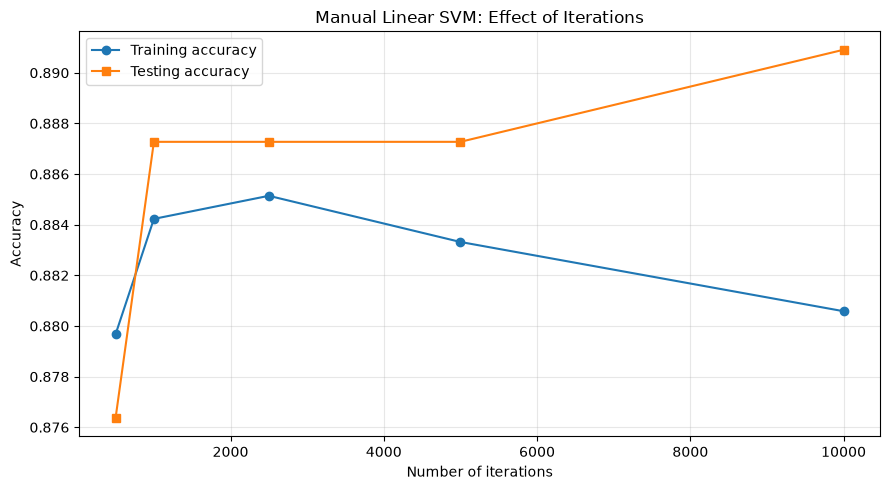

In [144]:
iteration_results = []

for n_iter in [500, 1000, 2500, 5000, 10000]:
    model = ManualLinearSVM(
        C=0.1,
        learning_rate=1e-5,
        n_iterations=n_iter
    )

    model.fit(X_train_svm, y_train_svm)

    train_predictions = model.predict(X_train_svm)
    test_predictions = model.predict(X_test_svm)

    iteration_results.append({
        "Iterations": n_iter,
        "Train accuracy": accuracy_score(y_train_svm, train_predictions),
        "Test accuracy": accuracy_score(y_test_svm, test_predictions),
        "Weight norm": np.linalg.norm(model.w),
        "Final objective": model.loss_history_[-1]
    })

iteration_comparison = pd.DataFrame(iteration_results)
display(iteration_comparison.round(6))

plt.figure(figsize=(9, 5))
plt.plot(
    iteration_comparison["Iterations"],
    iteration_comparison["Train accuracy"],
    marker="o",
    label="Training accuracy"
)
plt.plot(
    iteration_comparison["Iterations"],
    iteration_comparison["Test accuracy"],
    marker="s",
    label="Testing accuracy"
)
plt.xlabel("Number of iterations")
plt.ylabel("Accuracy")
plt.title("Manual Linear SVM: Effect of Iterations")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Best Manual Model and Margin Visualization

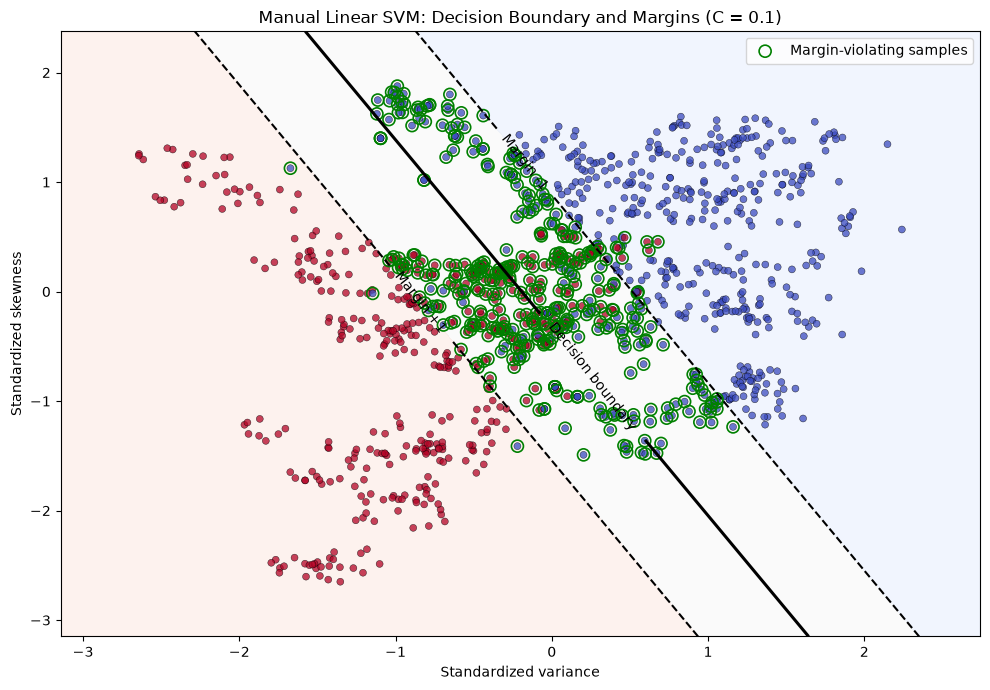

Selected C: 0.1
Test accuracy: 0.8909
Margin violations: 407 / 1097
Weight norm: 1.6363
Geometric margin width: 1.2223


In [145]:
# Refit the selected model using the same training split
best_manual_svm = ManualLinearSVM(
    C=0.1,
    learning_rate=1e-5,
    n_iterations=10000
)
best_manual_svm.fit(X_train_svm, y_train_svm)

train_scores = best_manual_svm.decision_function(X_train_svm)
margin_values = y_train_svm * train_scores
violations = margin_values < 1

# Create a grid in standardized feature space
x_min, x_max = X_train_svm[:, 0].min() - 0.5, X_train_svm[:, 0].max() + 0.5
y_min, y_max = X_train_svm[:, 1].min() - 0.5, X_train_svm[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_scores = best_manual_svm.decision_function(grid).reshape(xx.shape)

plt.figure(figsize=(10, 7))
plt.contourf(
    xx, yy, grid_scores,
    levels=[-100, -1, 0, 1, 100],
    alpha=0.12,
    cmap="coolwarm"
)

# Exact decision boundary and margin levels
contours = plt.contour(
    xx, yy, grid_scores,
    levels=[-1, 0, 1],
    colors=["black", "black", "black"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2.2, 1.5]
)
plt.clabel(contours, fmt={-1: "Margin -1", 0: "Decision boundary", 1: "Margin +1"})

plt.scatter(
    X_train_svm[:, 0], X_train_svm[:, 1],
    c=y_train_svm,
    cmap="coolwarm",
    edgecolors="black",
    linewidths=0.35,
    s=25,
    alpha=0.75
)

plt.scatter(
    X_train_svm[violations, 0],
    X_train_svm[violations, 1],
    facecolors="none",
    edgecolors="green",
    s=75,
    linewidths=1.2,
    label="Margin-violating samples"
)

plt.xlabel("Standardized variance")
plt.ylabel("Standardized skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins (C = 0.1)")
plt.legend()
plt.tight_layout()
plt.show()

best_svm_test_pred = np.where(
    best_manual_svm.predict(X_test_svm) == -1, 0, 1
)

print("Selected C:", best_manual_svm.C)
print("Test accuracy:", round(accuracy_score(y_test, best_svm_test_pred), 4))
print("Margin violations:", int(violations.sum()), "/", len(y_train_svm))
print("Weight norm:", round(np.linalg.norm(best_manual_svm.w), 4))
print("Geometric margin width:", round(2 / np.linalg.norm(best_manual_svm.w), 4))

# Part C - Kernel SVM and Nonlinear Boundaries

## Generate a Nonlinear Dataset

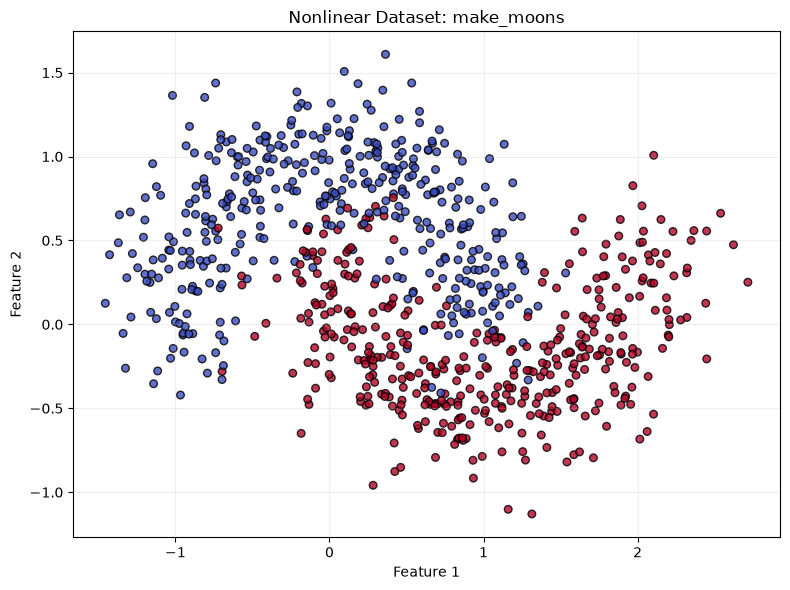

Nonlinear dataset generated successfully.
Total samples: 1000
Training samples: 800
Testing samples: 200
Number of features: 2
Training class distribution:
0    400
1    400
Name: count, dtype: int64


In [146]:
# Generate two interleaving moon-shaped classes
X_moons, y_moons = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=RANDOM_STATE
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_moons
)

# Visualize the generated dataset
plt.figure(figsize=(8, 6))
plt.scatter(
    X_moons_train[:, 0],
    X_moons_train[:, 1],
    c=y_moons_train,
    cmap="coolwarm",
    edgecolors="black",
    s=30,
    alpha=0.8
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: make_moons")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Nonlinear dataset generated successfully.")
print("Total samples:", len(X_moons))
print("Training samples:", len(X_moons_train))
print("Testing samples:", len(X_moons_test))
print("Number of features:", X_moons.shape[1])
print("Training class distribution:")
print(pd.Series(y_moons_train).value_counts().sort_index())

## Train and Compare Different Kernels

In [147]:
kernel_models = {
    "Linear": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),
    "Polynomial": make_pipeline(
        StandardScaler(),
        SVC(kernel="poly", degree=3, C=1.0, gamma="scale")
    ),
    "RBF": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    )
}

kernel_results = []

for kernel_name, model in kernel_models.items():
    start_time = time.perf_counter()
    model.fit(X_moons_train, y_moons_train)
    training_time = time.perf_counter() - start_time

    start_time = time.perf_counter()
    predictions = model.predict(X_moons_test)
    prediction_time = time.perf_counter() - start_time

    kernel_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(y_moons_test, predictions, zero_division=0),
        "Recall": recall_score(y_moons_test, predictions, zero_division=0),
        "F1-score": f1_score(y_moons_test, predictions, zero_division=0),
        "Training time (s)": training_time,
        "Prediction time (s)": prediction_time
    })

kernel_comparison = pd.DataFrame(kernel_results)

display(kernel_comparison.round(5))

,Kernel,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Linear,0.915,0.93684,0.89,0.91282,0.01833,0.00230
1,Polynomial,0.905,0.90099,0.91,0.90547,0.01081,0.00192
2,RBF,0.965,0.96040,0.97,0.96517,0.00824,0.00329


## Decision Boundary Comparison

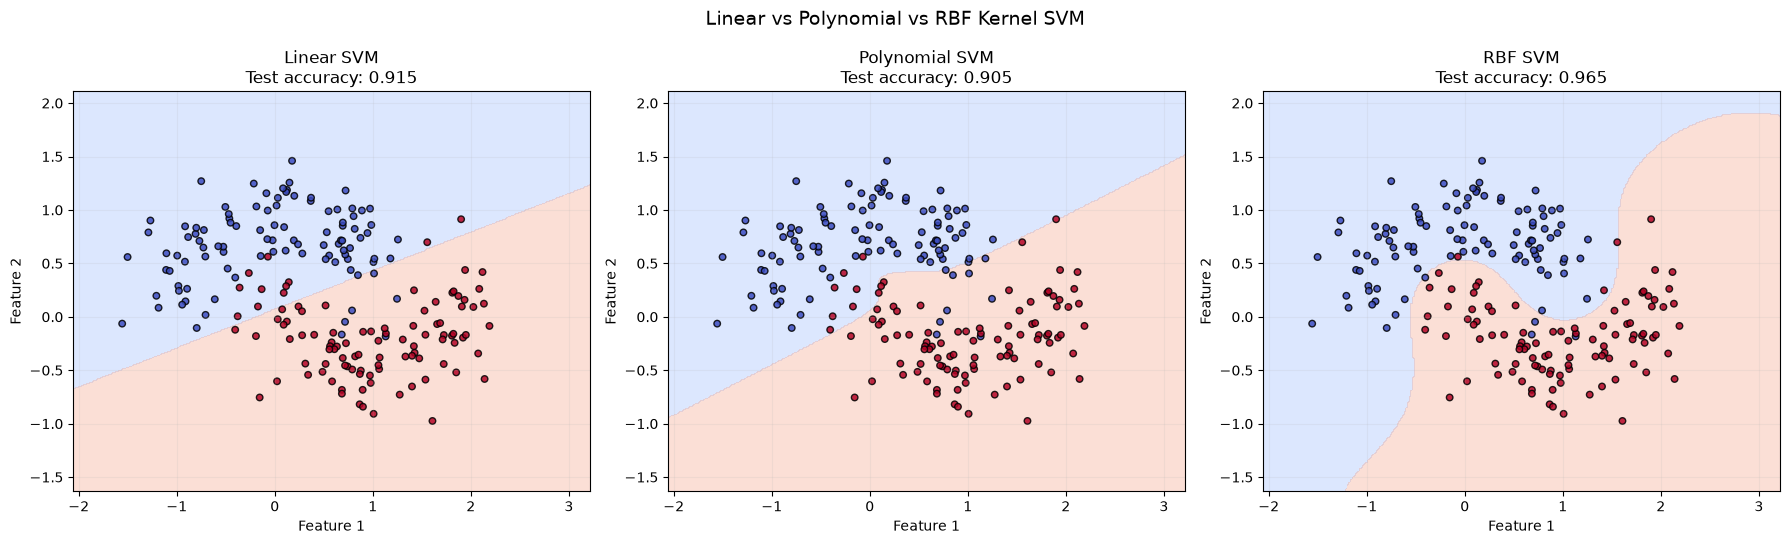

In [158]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

for ax, (kernel_name, model) in zip(axes, kernel_models.items()):
    # Predict the class for each point on the grid
    grid_predictions = model.predict(grid_points).reshape(xx.shape)

    ax.contourf(
        xx, yy, grid_predictions,
        levels=[-0.5, 0.5, 1.5],
        cmap="coolwarm",
        alpha=0.3
    )

    # Plot the test samples
    ax.scatter(
        X_moons_test[:, 0],
        X_moons_test[:, 1],
        c=y_moons_test,
        cmap="coolwarm",
        edgecolors="black",
        s=22,
        alpha=0.85
    )

    accuracy = accuracy_score(
        y_moons_test,
        model.predict(X_moons_test)
    )

    ax.set_title(f"{kernel_name} SVM\nTest accuracy: {accuracy:.3f}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(alpha=0.15)

plt.suptitle("Linear vs Polynomial vs RBF Kernel SVM", fontsize=14)
plt.tight_layout()
plt.show()

# Part D - Final Comparison

## Prepare All Four Banknote Features

In [149]:
# Use all four original features for final evaluation
feature_columns = ["variance", "skewness", "curtosis", "entropy"]

X_full = df[feature_columns].to_numpy(dtype=float)
y_full = df["class"].to_numpy(dtype=int)

# Same split settings as the earlier two-feature experiment
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_full
)

print("Four-feature dataset prepared.")
print("Features:", feature_columns)
print("Training shape:", X_train_full.shape)
print("Testing shape:", X_test_full.shape)
print("Training classes:")
print(pd.Series(y_train_full).value_counts().sort_index())
print("Testing classes:")
print(pd.Series(y_test_full).value_counts().sort_index())

# Confirm that the full-feature split uses the same observations
# as the two-feature split, assuming both used the same split settings.
print("\nTraining labels match earlier split:",
      np.array_equal(y_train_full, y_train))
print("Testing labels match earlier split:",
      np.array_equal(y_test_full, y_test))

Four-feature dataset prepared.
Features: ['variance', 'skewness', 'curtosis', 'entropy']
Training shape: (1097, 4)
Testing shape: (275, 4)
Training classes:
0    609
1    488
Name: count, dtype: int64
Testing classes:
0    153
1    122
Name: count, dtype: int64

Training labels match earlier split: True
Testing labels match earlier split: True


## Train Four-Feature Classifiers

In [150]:
# Fit scaling parameters on training data only
scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

# 1. Manual Linear SVM from scratch
manual_svm_full = ManualLinearSVM(
    C=0.1,
    learning_rate=1e-5,
    n_iterations=10000
)

start = time.perf_counter()
manual_svm_full.fit(X_train_full_scaled, np.where(y_train_full == 0, -1, 1))
manual_svm_full_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_svm_full_signed = manual_svm_full.predict(X_test_full_scaled)
manual_svm_full_pred = np.where(manual_svm_full_signed == -1, 0, 1)
manual_svm_full_predict_time = time.perf_counter() - start

# 2. Scikit-learn Decision Tree
tree_full = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=RANDOM_STATE
)

start = time.perf_counter()
tree_full.fit(X_train_full, y_train_full)
tree_full_train_time = time.perf_counter() - start

start = time.perf_counter()
tree_full_pred = tree_full.predict(X_test_full)
tree_full_predict_time = time.perf_counter() - start

# 3. Scikit-learn Linear SVM
linear_svm_full = SVC(kernel="linear", C=0.1)

start = time.perf_counter()
linear_svm_full.fit(X_train_full_scaled, y_train_full)
linear_svm_full_train_time = time.perf_counter() - start

start = time.perf_counter()
linear_svm_full_pred = linear_svm_full.predict(X_test_full_scaled)
linear_svm_full_predict_time = time.perf_counter() - start

# 4. Scikit-learn RBF SVM
rbf_svm_full = SVC(kernel="rbf", C=1.0, gamma="scale")

start = time.perf_counter()
rbf_svm_full.fit(X_train_full_scaled, y_train_full)
rbf_svm_full_train_time = time.perf_counter() - start

start = time.perf_counter()
rbf_svm_full_pred = rbf_svm_full.predict(X_test_full_scaled)
rbf_svm_full_predict_time = time.perf_counter() - start

print("Four-feature models trained successfully.")
print("Manual SVM weights:", np.round(manual_svm_full.w, 4))
print("Manual SVM bias:", round(manual_svm_full.b, 4))
print("Scikit-learn tree depth:", tree_full.get_depth())
print("Scikit-learn tree leaves:", tree_full.get_n_leaves())
print("Manual SVM test predictions:", len(manual_svm_full_pred))
print("Scikit-learn tree test predictions:", len(tree_full_pred))
print("Linear SVM test predictions:", len(linear_svm_full_pred))
print("RBF SVM test predictions:", len(rbf_svm_full_pred))

Four-feature models trained successfully.
Manual SVM weights: [-1.3528 -1.1118 -1.0758  0.1566]
Manual SVM bias: -0.1993
Scikit-learn tree depth: 5
Scikit-learn tree leaves: 14
Manual SVM test predictions: 275
Scikit-learn tree test predictions: 275
Linear SVM test predictions: 275
RBF SVM test predictions: 275


## Manual Decision Tree from Scratch

In [ ]:
def count_manual_leaves(node):
    if "feature_idx" not in node:
        return 1

    return (
        count_manual_leaves(node["left"])
        + count_manual_leaves(node["right"])
    )

# Train the existing manual decision tree on all four features
manual_tree_full = ManualDecisionTree(
    criterion="entropy",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

start = time.perf_counter()
manual_tree_full.fit(X_train_full, y_train_full)
manual_tree_full_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_tree_full_pred = manual_tree_full.predict(X_test_full)
manual_tree_full_predict_time = time.perf_counter() - start

print("Manual decision tree trained on all four features.")
print("Criterion:", manual_tree_full.criterion)
print("Maximum allowed depth:", manual_tree_full.max_depth)
print("Actual depth:", _get_manual_tree_depth(manual_tree_full.tree_))
print("Number of leaves:", count_manual_leaves(manual_tree_full.tree_))

print(
    f"Test accuracy: "
    f"{accuracy_score(y_test_full, manual_tree_full_pred):.4f}"
)

Manual decision tree trained on four features.
Actual depth: 5
Number of leaves: 14
Test accuracy: 0.9855
Manual four-feature decision tree trained.
Criterion: entropy
Maximum depth: 5
Actual depth: 5
Number of leaves: 14
Test accuracy: 0.9855


## All Five Models Using Four Features

In [160]:

all_five_models = [
    (
        "Manual Decision Tree",
        manual_tree_full_pred,
        manual_tree_full_train_time,
        manual_tree_full_predict_time
    ),
    (
        "Scikit-learn Decision Tree",
        tree_full_pred,
        tree_full_train_time,
        tree_full_predict_time
    ),
    (
        "Manual Linear SVM",
        manual_svm_full_pred,
        manual_svm_full_train_time,
        manual_svm_full_predict_time
    ),
    (
        "Scikit-learn Linear SVM",
        linear_svm_full_pred,
        linear_svm_full_train_time,
        linear_svm_full_predict_time
    ),
    (
        "Scikit-learn RBF SVM",
        rbf_svm_full_pred,
        rbf_svm_full_train_time,
        rbf_svm_full_predict_time
    )
]

final_rows = []

for name, predictions, train_time, predict_time in all_five_models:
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_full, predictions),
        "Precision": precision_score(
            y_test_full, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_full, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_full, predictions, zero_division=0
        ),
        "Training time (s)": train_time,
        "Prediction time (s)": predict_time
    })

final_comparison = pd.DataFrame(final_rows).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(final_comparison.round(5))

print("\nEvaluation setup:")
print("Training samples:", len(X_train_full))
print("Testing samples:", len(X_test_full))
print("Features:", feature_columns)
print("All models use the same train-test split.")

best_model = final_comparison.iloc[0]

print("\nBest model on this test split:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"F1-score: {best_model['F1-score']:.4f}")

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Scikit-learn RBF SVM,1.00000,1.00000,1.0000,1.00000,0.00659,0.00251
1,Manual Decision Tree,0.98545,0.97581,0.9918,0.98374,0.39972,0.00032
2,Scikit-learn Decision Tree,0.98545,0.97581,0.9918,0.98374,0.00516,0.00036
3,Manual Linear SVM,0.97091,0.93846,1.0000,0.96825,0.46210,0.00015
4,Scikit-learn Linear SVM,0.97091,0.93846,1.0000,0.96825,0.00983,0.00133



Evaluation setup:
Training samples: 1097
Testing samples: 275
Features: ['variance', 'skewness', 'curtosis', 'entropy']
All models use the same train-test split.

Best model on this test split: Scikit-learn RBF SVM
Accuracy: 1.0000
F1-score: 1.0000
